# META: stationarity, volatility, and trend signals

**Original course notebook with saved outputs.** Matias Freer handled these sections of a group project with Sarah Bottom and Vincent Guerrero.

Outputs are from the original Colab run, not an independent regeneration from its original price snapshot. The original code includes a date-range overwrite and redundant exploration. Use analysis.py for the separate portfolio edition with fixed dates and explicit adjusted prices. Its results may differ.

Forecasting and financial-event analysis were broader team work.


In [ ]:
# Import the yfinance library to download stock market data
import yfinance as yf

# Define the ticker symbol
# Replace 'AMZN' with your team's chosen company ticker
# Examples: 'MSFT' = Microsoft, 'TSLA' = Tesla, 'AAPL' = Apple
ticker_symbol = 'META'  # Amazon is shown here as the demo we will cover in class; change this to your group's choosen company

# Create a Ticker object — this is your connection to that company's data on Yahoo Finance
ticker_data = yf.Ticker(ticker_symbol)

# Define the date range for the historical data
# We are pulling approximately 5 years of data: Jan 2020 through Jan 2026
# This range includes COVID-19, the 2022 market correction, political elections, and the AI boom; all analytically rich periods
start_date = '2021-01-01'
end_date = '2026-01-01'

# Download the historical daily price data for your chosen ticker
# The result is a pandas DataFrame with columns like Open, High, Low, Close, and Volume
amazon_df = ticker_data.history(start=start_date, end=end_date)

# Preview the first five rows to confirm the download worked correctly
amazon_df.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2021-01-04 00:00:00-05:00,272.173204,272.391118,262.684101,266.388611,15106100,0.0,0.0
2021-01-05 00:00:00-05:00,265.744785,269.815780,265.665527,268.399353,9871600,0.0,0.0
2021-01-06 00:00:00-05:00,259.514442,265.209892,257.543330,260.812012,24354100,0.0,0.0
2021-01-07 00:00:00-05:00,263.377377,269.033197,262.268007,266.190430,15789800,0.0,0.0
2021-01-08 00:00:00-05:00,265.764556,266.398499,260.683219,265.031586,18528300,0.0,0.0


In [ ]:
import yfinance as yf

amazon_df = yf.download("META", start="2021-01-01")

/tmp/ipykernel_2481/4170869805.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  amazon_df = yf.download("META", start="2021-01-01")
[*********************100%***********************]  1 of 1 completed


In [ ]:
amazon_df.head()

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2021-01-04,266.388641,272.391149,262.684131,272.173235,15106100
2021-01-05,268.399353,269.815780,265.665527,265.744785,9871600
2021-01-06,260.812042,265.209923,257.543361,259.514472,24354100
2021-01-07,266.190521,269.033289,262.268097,263.377467,15789800
2021-01-08,265.031586,266.398499,260.683219,265.764556,18528300


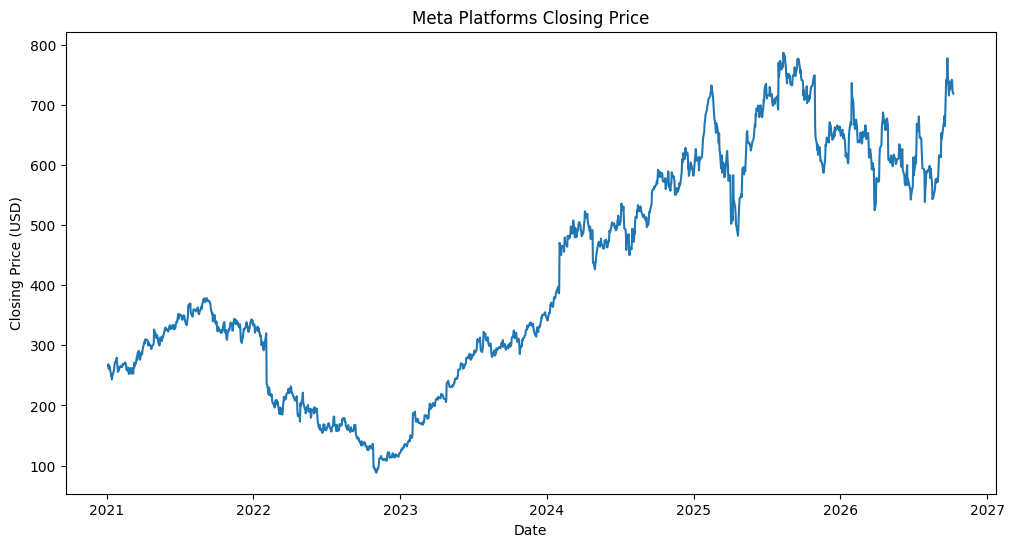

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(amazon_df.index, amazon_df["Close"])
plt.title("Meta Platforms Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.show()

In [ ]:
from statsmodels.tsa.stattools import adfuller

close_prices = amazon_df["Close"].dropna()

# If yfinance returned Close as a one-column DataFrame,
# convert it to a Series.
if close_prices.ndim > 1:
    close_prices = close_prices.squeeze()

adf_result = adfuller(close_prices)

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:")
for key, value in adf_result[4].items():
    print(f"   {key}: {value}")

ADF Statistic: -0.6035515226615039
p-value: 0.8701775071419018
Critical Values:
   1%: -3.4348772553489617
   5%: -2.8635394783531085
   10%: -2.5678345067434516


/tmp/ipykernel_2481/3492697767.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(close_prices)


In [ ]:
meta_diff = amazon_df["Close"].diff().dropna()

if meta_diff.ndim > 1:
    meta_diff = meta_diff.squeeze()

adf_diff_result = adfuller(meta_diff)

print("ADF Statistic:", adf_diff_result[0])
print("p-value:", adf_diff_result[1])
print("Critical Values:")
for key, value in adf_diff_result[4].items():
    print(f"   {key}: {value}")

ADF Statistic: -39.835094265931126
p-value: 0.0
Critical Values:
   1%: -3.4348772553489617
   5%: -2.8635394783531085
   10%: -2.5678345067434516


/tmp/ipykernel_2481/1158006866.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff_result = adfuller(meta_diff)


<Figure size 1000x500 with 0 Axes>

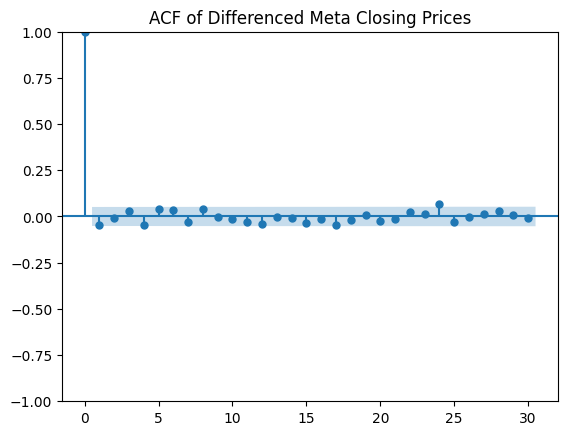

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plot_acf(meta_diff, lags=30)
plt.title("ACF of Differenced Meta Closing Prices")
plt.show()

<Figure size 1000x500 with 0 Axes>

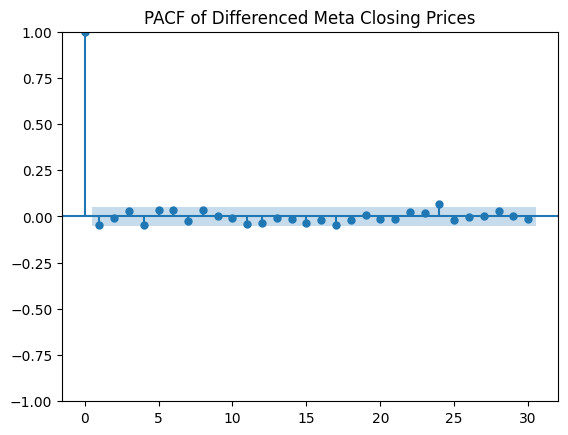

In [ ]:
plt.figure(figsize=(10, 5))
plot_pacf(meta_diff, lags=30, method="ywm")
plt.title("PACF of Differenced Meta Closing Prices")
plt.show()

In [ ]:
import numpy as np

amazon_df["Pct_Change"] = amazon_df["Close"].pct_change() * 100

amazon_df["Log_Return"] = np.log(
    amazon_df["Close"] / amazon_df["Close"].shift(1)
)

In [ ]:
large_moves = amazon_df[
    amazon_df["Pct_Change"].abs() > 5
][["Close", "Pct_Change", "Volume"]]

large_moves

Price,Close,Pct_Change,Volume
Ticker,META,,META
Date,,,


In [15]:
import pandas as pd
import numpy as np

# Convert the yfinance columns we need into simple Series
close = amazon_df["Close"].squeeze()
volume = amazon_df["Volume"].squeeze()

# Create a simple analysis DataFrame
meta_analysis = pd.DataFrame({
    "Close": close,
    "Volume": volume
})

# Calculate daily percent change and log return
meta_analysis["Pct_Change"] = meta_analysis["Close"].pct_change() * 100

meta_analysis["Log_Return"] = np.log(
    meta_analysis["Close"] / meta_analysis["Close"].shift(1)
)

# Find days where Meta moved more than 5% in either direction
large_moves = meta_analysis[
    meta_analysis["Pct_Change"].abs() > 5
]

large_moves

,Close,Volume,Pct_Change,Log_Return
Date,,,,
2021-04-29,326.384003,56526800,7.297293,0.070433
2021-07-23,366.281921,33694300,5.296299,0.051608
2021-10-22,321.530426,35224500,-5.051509,-0.051836
2022-02-03,235.504410,188119900,-26.390102,-0.306391
2022-02-07,222.776321,88613800,-5.137278,-0.052739
...,...,...,...,...
2026-07-10,668.682312,40608900,5.974864,0.058032
2026-07-30,538.604980,42271500,-7.954090,-0.082883
2026-08-03,589.774536,25938100,6.022881,0.058485


In [16]:
# Calculate mean and standard deviation of daily percent changes
mean_return = meta_analysis["Pct_Change"].mean()
std_return = meta_analysis["Pct_Change"].std()

# Define 3-standard-deviation boundaries
upper_bound = mean_return + (3 * std_return)
lower_bound = mean_return - (3 * std_return)

print("Mean Daily % Change:", mean_return)
print("Standard Deviation:", std_return)
print("Upper 3-SD Boundary:", upper_bound)
print("Lower 3-SD Boundary:", lower_bound)

Mean Daily % Change: 0.10635100867701583
Standard Deviation: 2.737761462825
Upper 3-SD Boundary: 8.319635397152016
Lower 3-SD Boundary: -8.106933379797983


In [17]:
outliers = meta_analysis[
    (meta_analysis["Pct_Change"] > upper_bound) |
    (meta_analysis["Pct_Change"] < lower_bound)
]

outliers

,Close,Volume,Pct_Change,Log_Return
Date,,,,
2022-02-03,235.504410,188119900,-26.390102,-0.306391
2022-04-28,203.778275,100890600,17.593606,0.162064
2022-09-13,151.677307,44444100,-9.369064,-0.098375
2022-10-27,97.010857,232316600,-24.557084,-0.281794
2022-11-10,110.808708,80671000,10.249319,0.097574
2023-02-02,186.979187,150475700,23.282418,0.209308
2023-04-27,236.296844,71196500,13.925515,0.130375
2024-02-02,470.483795,84707600,20.317640,0.184965
2024-04-25,437.656586,82890700,-10.561298,-0.111617


In [18]:
outliers_sorted = outliers.copy()

outliers_sorted["Abs_Change"] = outliers_sorted["Pct_Change"].abs()

outliers_sorted = outliers_sorted.sort_values(
    "Abs_Change",
    ascending=False
)

outliers_sorted


,Close,Volume,Pct_Change,Log_Return,Abs_Change
Date,,,,,
2022-02-03,235.504410,188119900,-26.390102,-0.306391,26.390102
2022-10-27,97.010857,232316600,-24.557084,-0.281794,24.557084
2023-02-02,186.979187,150475700,23.282418,0.209308,23.282418
2024-02-02,470.483795,84707600,20.317640,0.184965,20.317640
2022-04-28,203.778275,100890600,17.593606,0.162064,17.593606
2025-04-09,582.947449,39216600,14.755613,0.137635,14.755613
2023-04-27,236.296844,71196500,13.925515,0.130375,13.925515
2026-09-21,741.250000,48720500,11.428458,0.108213,11.428458
2025-10-30,664.216919,88440100,-11.334756,-0.120302,11.334756


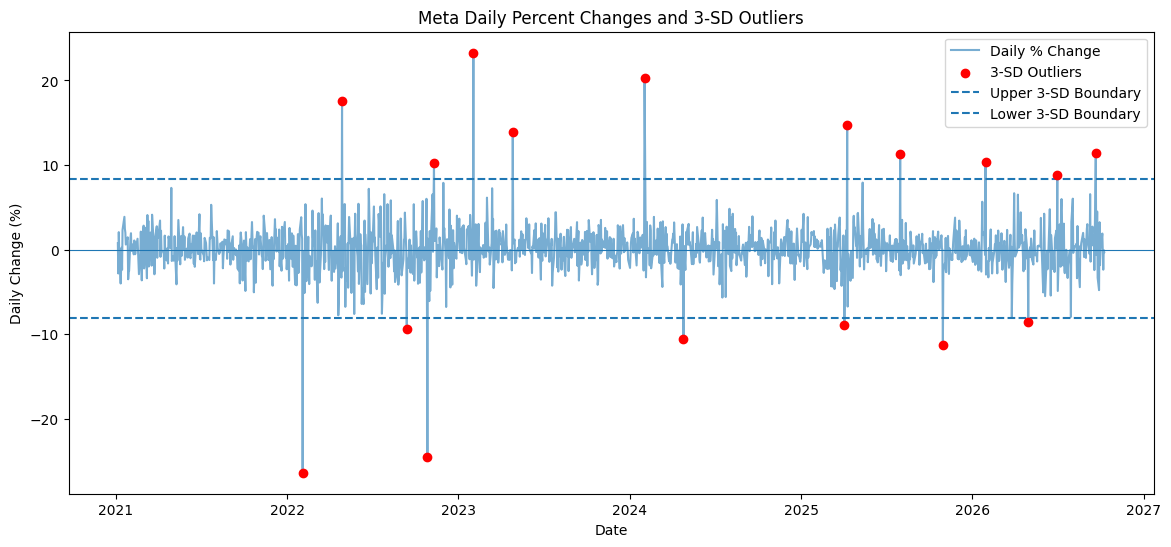

In [19]:
plt.figure(figsize=(14, 6))

plt.plot(
    meta_analysis.index,
    meta_analysis["Pct_Change"],
    label="Daily % Change",
    alpha=0.6
)

plt.scatter(
    outliers.index,
    outliers["Pct_Change"],
    color="red",
    label="3-SD Outliers",
    zorder=5
)

plt.axhline(upper_bound, linestyle="--", label="Upper 3-SD Boundary")
plt.axhline(lower_bound, linestyle="--", label="Lower 3-SD Boundary")
plt.axhline(0, linewidth=0.8)

plt.title("Meta Daily Percent Changes and 3-SD Outliers")
plt.xlabel("Date")
plt.ylabel("Daily Change (%)")
plt.legend()

plt.show()

In [20]:
high_volume_days = meta_analysis.sort_values(
    "Volume",
    ascending=False
).head(15)

high_volume_days

,Close,Volume,Pct_Change,Log_Return
Date,,,,
2022-10-27,97.010857,232316600,-24.557084,-0.281794
2022-02-03,235.504410,188119900,-26.390102,-0.306391
2023-02-02,186.979187,150475700,23.282418,0.209308
2022-10-31,92.276222,121361400,-6.088699,-0.062819
2022-11-01,94.296852,110189600,2.189762,0.021661
2022-11-09,100.507385,107677300,5.182969,0.050531
2022-04-28,203.778275,100890600,17.593606,0.162064
2022-10-28,98.258911,95928300,1.286510,0.012783
2022-02-08,218.091171,94729700,-2.103074,-0.021255


In [21]:
volume_threshold = meta_analysis["Volume"].quantile(0.95)

print("95th Percentile Volume Threshold:", volume_threshold)

high_volume = meta_analysis[
    meta_analysis["Volume"] > volume_threshold
]

high_volume.sort_values(
    "Volume",
    ascending=False
).head(20)

95th Percentile Volume Threshold: 43260239.99999998


,Close,Volume,Pct_Change,Log_Return
Date,,,,
2022-10-27,97.010857,232316600,-24.557084,-0.281794
2022-02-03,235.504410,188119900,-26.390102,-0.306391
2023-02-02,186.979187,150475700,23.282418,0.209308
2022-10-31,92.276222,121361400,-6.088699,-0.062819
2022-11-01,94.296852,110189600,2.189762,0.021661
2022-11-09,100.507385,107677300,5.182969,0.050531
2022-04-28,203.778275,100890600,17.593606,0.162064
2022-10-28,98.258911,95928300,1.286510,0.012783
2022-02-08,218.091171,94729700,-2.103074,-0.021255


In [22]:
outlier_high_volume = outliers[
    outliers["Volume"] > volume_threshold
].sort_values(
    "Volume",
    ascending=False
)

outlier_high_volume

,Close,Volume,Pct_Change,Log_Return
Date,,,,
2022-10-27,97.010857,232316600,-24.557084,-0.281794
2022-02-03,235.504410,188119900,-26.390102,-0.306391
2023-02-02,186.979187,150475700,23.282418,0.209308
2022-04-28,203.778275,100890600,17.593606,0.162064
2025-10-30,664.216919,88440100,-11.334756,-0.120302
2024-02-02,470.483795,84707600,20.317640,0.184965
2024-04-25,437.656586,82890700,-10.561298,-0.111617
2022-11-10,110.808708,80671000,10.249319,0.097574
2023-04-27,236.296844,71196500,13.925515,0.130375


In [23]:
meta_analysis["MA_30"] = meta_analysis["Close"].rolling(30).mean()
meta_analysis["MA_90"] = meta_analysis["Close"].rolling(90).mean()
meta_analysis["MA_180"] = meta_analysis["Close"].rolling(180).mean()

meta_analysis["MA_50"] = meta_analysis["Close"].rolling(50).mean()
meta_analysis["MA_200"] = meta_analysis["Close"].rolling(200).mean()

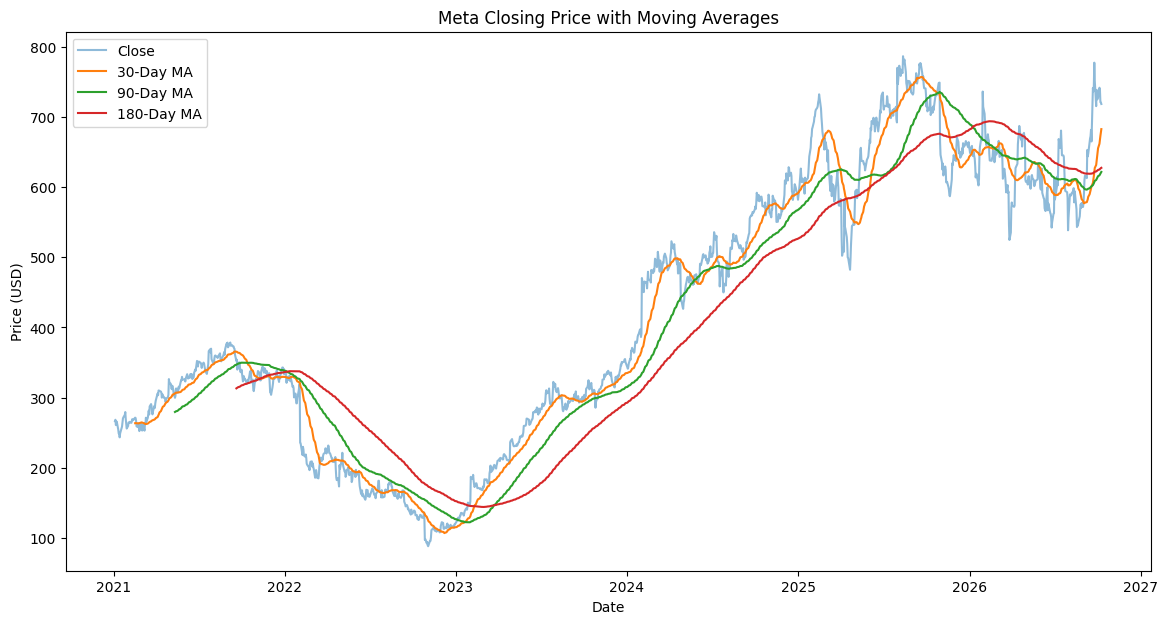

In [24]:
plt.figure(figsize=(14, 7))

plt.plot(
    meta_analysis.index,
    meta_analysis["Close"],
    label="Close",
    alpha=0.5
)

plt.plot(
    meta_analysis.index,
    meta_analysis["MA_30"],
    label="30-Day MA"
)

plt.plot(
    meta_analysis.index,
    meta_analysis["MA_90"],
    label="90-Day MA"
)

plt.plot(
    meta_analysis.index,
    meta_analysis["MA_180"],
    label="180-Day MA"
)

plt.title("Meta Closing Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()

plt.show()

In [25]:
meta_analysis["MA_Difference"] = (
    meta_analysis["MA_50"] - meta_analysis["MA_200"]
)

meta_analysis["Cross"] = np.sign(
    meta_analysis["MA_Difference"]
).diff()

golden_crosses = meta_analysis[
    meta_analysis["Cross"] == 2
]

death_crosses = meta_analysis[
    meta_analysis["Cross"] == -2
]

print("Golden Crosses:")
display(
    golden_crosses[
        ["Close", "MA_50", "MA_200"]
    ]
)

print("Death Crosses:")
display(
    death_crosses[
        ["Close", "MA_50", "MA_200"]
    ]
)

Golden Crosses:


,Close,MA_50,MA_200
Date,,,
2023-03-02,172.874252,148.688505,148.487531
2025-06-16,699.274414,601.436744,599.018773
2026-10-06,738.880005,630.516332,628.274652


Death Crosses:


,Close,MA_50,MA_200
Date,,,
2021-12-10,326.621704,327.418887,327.492973
2025-05-06,584.480042,577.251092,577.324937
2025-12-10,647.932190,668.147195,668.489757


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [26]:
# Golden Cross:
# 50-day MA is now above the 200-day MA,
# but yesterday it was at or below it

golden_crosses = meta_analysis[
    (meta_analysis["MA_50"] > meta_analysis["MA_200"]) &
    (meta_analysis["MA_50"].shift(1) <= meta_analysis["MA_200"].shift(1))
]

# Death Cross:
# 50-day MA is now below the 200-day MA,
# but yesterday it was at or above it

death_crosses = meta_analysis[
    (meta_analysis["MA_50"] < meta_analysis["MA_200"]) &
    (meta_analysis["MA_50"].shift(1) >= meta_analysis["MA_200"].shift(1))
]

print("Golden Crosses:")
display(
    golden_crosses[
        ["Close", "MA_50", "MA_200"]
    ]
)

print("Death Crosses:")
display(
    death_crosses[
        ["Close", "MA_50", "MA_200"]
    ]
)

Golden Crosses:


,Close,MA_50,MA_200
Date,,,
2023-03-02,172.874252,148.688505,148.487531
2025-06-16,699.274414,601.436744,599.018773
2026-10-06,738.880005,630.516332,628.274652


Death Crosses:


,Close,MA_50,MA_200
Date,,,
2021-12-10,326.621704,327.418887,327.492973
2025-05-06,584.480042,577.251092,577.324937
2025-12-10,647.932190,668.147195,668.489757


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


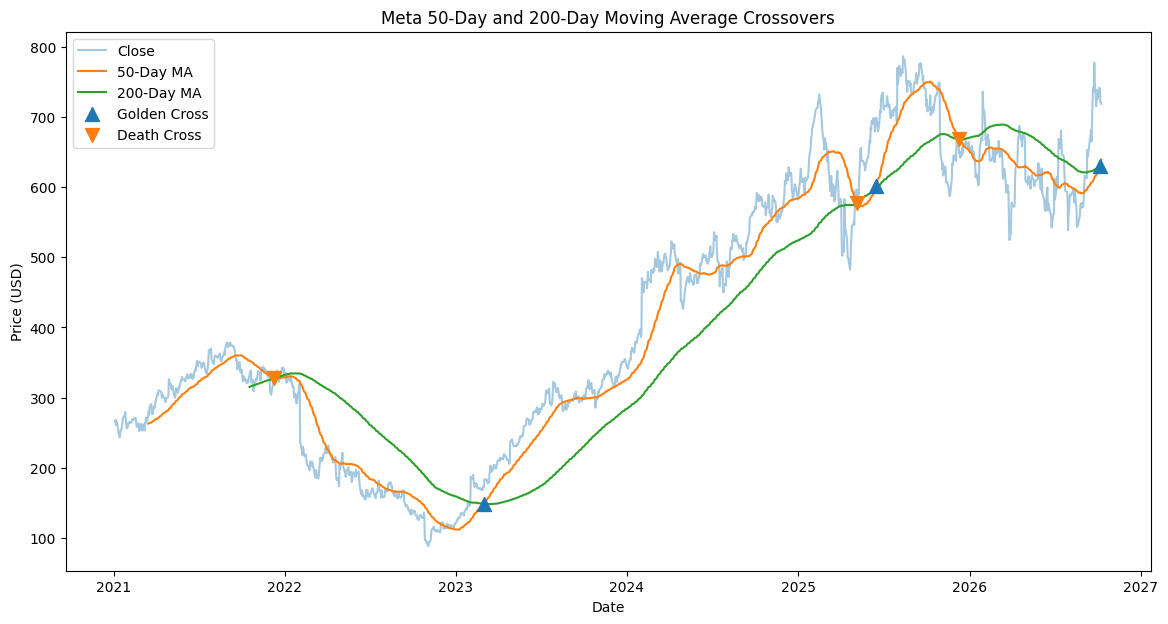

In [27]:
plt.figure(figsize=(14, 7))

plt.plot(
    meta_analysis.index,
    meta_analysis["Close"],
    label="Close",
    alpha=0.4
)

plt.plot(
    meta_analysis.index,
    meta_analysis["MA_50"],
    label="50-Day MA"
)

plt.plot(
    meta_analysis.index,
    meta_analysis["MA_200"],
    label="200-Day MA"
)

plt.scatter(
    golden_crosses.index,
    golden_crosses["MA_50"],
    marker="^",
    s=100,
    label="Golden Cross",
    zorder=5
)

plt.scatter(
    death_crosses.index,
    death_crosses["MA_50"],
    marker="v",
    s=100,
    label="Death Cross",
    zorder=5
)

plt.title("Meta 50-Day and 200-Day Moving Average Crossovers")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()

plt.show()

In [28]:
print("Number of Golden Crosses:", len(golden_crosses))

for date, row in golden_crosses.iterrows():
    print(
        date.date(),
        "| Close:", round(row["Close"], 2),
        "| MA_50:", round(row["MA_50"], 2),
        "| MA_200:", round(row["MA_200"], 2)
    )

Number of Golden Crosses: 3
2023-03-02 | Close: 172.87 | MA_50: 148.69 | MA_200: 148.49
2025-06-16 | Close: 699.27 | MA_50: 601.44 | MA_200: 599.02
2026-10-06 | Close: 738.88 | MA_50: 630.52 | MA_200: 628.27


In [29]:
print("Number of Death Crosses:", len(death_crosses))

for date, row in death_crosses.iterrows():
    print(
        date.date(),
        "| Close:", round(row["Close"], 2),
        "| MA_50:", round(row["MA_50"], 2),
        "| MA_200:", round(row["MA_200"], 2)
    )

Number of Death Crosses: 3
2021-12-10 | Close: 326.62 | MA_50: 327.42 | MA_200: 327.49
2025-05-06 | Close: 584.48 | MA_50: 577.25 | MA_200: 577.32
2025-12-10 | Close: 647.93 | MA_50: 668.15 | MA_200: 668.49
